In [1]:
import pandas as pd
import numpy as np
import joblib
import shap

# Load saved model
bundle = joblib.load("../models/xgboost_final.pkl")

model = bundle["model"]
preprocessor = bundle["preprocessor"]
threshold = bundle["threshold"]
features = bundle["features"]

print("Model loaded successfully!")
print("Classification threshold:", threshold)
print("Features:", features)

Model loaded successfully!
Classification threshold: 0.4
Features: ['amt', 'category', 'hour', 'day_of_week', 'age', 'distance_km']


In [2]:
# Load original transaction data
df = pd.read_csv("../data/fraudTrain.csv")

# Convert dates
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df["dob"] = pd.to_datetime(df["dob"])

# Recreate engineered features
df["hour"] = df["trans_date_trans_time"].dt.hour
df["day_of_week"] = df["trans_date_trans_time"].dt.day_name()

df["age"] = (
    (df["trans_date_trans_time"] - df["dob"]).dt.days / 365.25
).astype(int)

# Calculate Haversine distance
R = 6371

lat1 = np.radians(df["lat"])
lon1 = np.radians(df["long"])
lat2 = np.radians(df["merch_lat"])
lon2 = np.radians(df["merch_long"])

a = (
    np.sin((lat2 - lat1) / 2) ** 2
    + np.cos(lat1) * np.cos(lat2)
    * np.sin((lon2 - lon1) / 2) ** 2
)

df["distance_km"] = 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

# Sample 500 transactions
sample = df.sample(n=500, random_state=42)

# Select original model features
X_sample = sample[features]

# Apply saved preprocessing
X_sample_processed = preprocessor.transform(X_sample)

print("Original sample shape:", X_sample.shape)
print("Processed sample shape:", X_sample_processed.shape)

Original sample shape: (500, 6)
Processed sample shape: (500, 25)


In [3]:
# Get names of the 25 processed features
feature_names = preprocessor.get_feature_names_out()

# Create SHAP explainer for XGBoost
explainer = shap.TreeExplainer(model)

# Calculate SHAP values for our 500 transactions
shap_values = explainer(X_sample_processed)

print("SHAP values calculated!")
print("SHAP shape:", shap_values.values.shape)
print("Number of features:", len(feature_names))

SHAP values calculated!
SHAP shape: (500, 25)
Number of features: 25


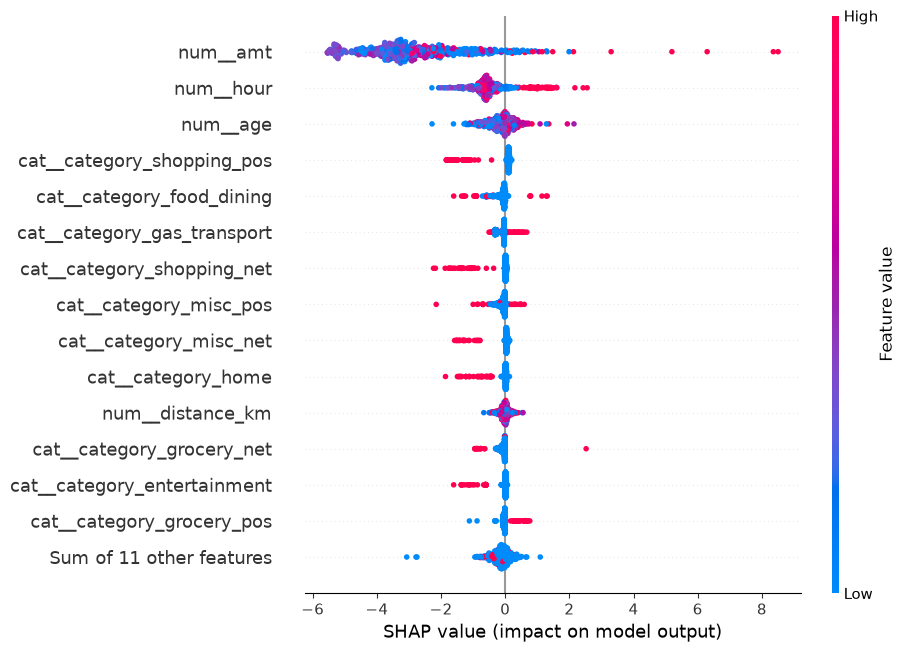

In [4]:
import matplotlib.pyplot as plt

# Assign readable feature names
shap_values.feature_names = feature_names.tolist()

# Display SHAP summary plot
shap.plots.beeswarm(shap_values, max_display=15)

plt.show()

In [5]:
# Predict fraud probabilities for our sample
fraud_probabilities = model.predict_proba(X_sample_processed)[:, 1]

# Find transactions predicted as fraud
fraud_indices = np.where(fraud_probabilities >= threshold)[0]

print("Transactions flagged as fraud:", len(fraud_indices))

if len(fraud_indices) > 0:
    transaction_idx = fraud_indices[0]

    print("\nSelected Transaction:")
    print(X_sample.iloc[transaction_idx])

    print("\nPredicted Fraud Probability:")
    print(f"{fraud_probabilities[transaction_idx]:.2%}")
else:
    print("No transactions flagged. We'll need a larger or fraud-focused sample.")

Transactions flagged as fraud: 4

Selected Transaction:
amt                  15.95
category       grocery_net
hour                     3
day_of_week      Wednesday
age                     56
distance_km     114.559732
Name: 307415, dtype: object

Predicted Fraud Probability:
66.70%


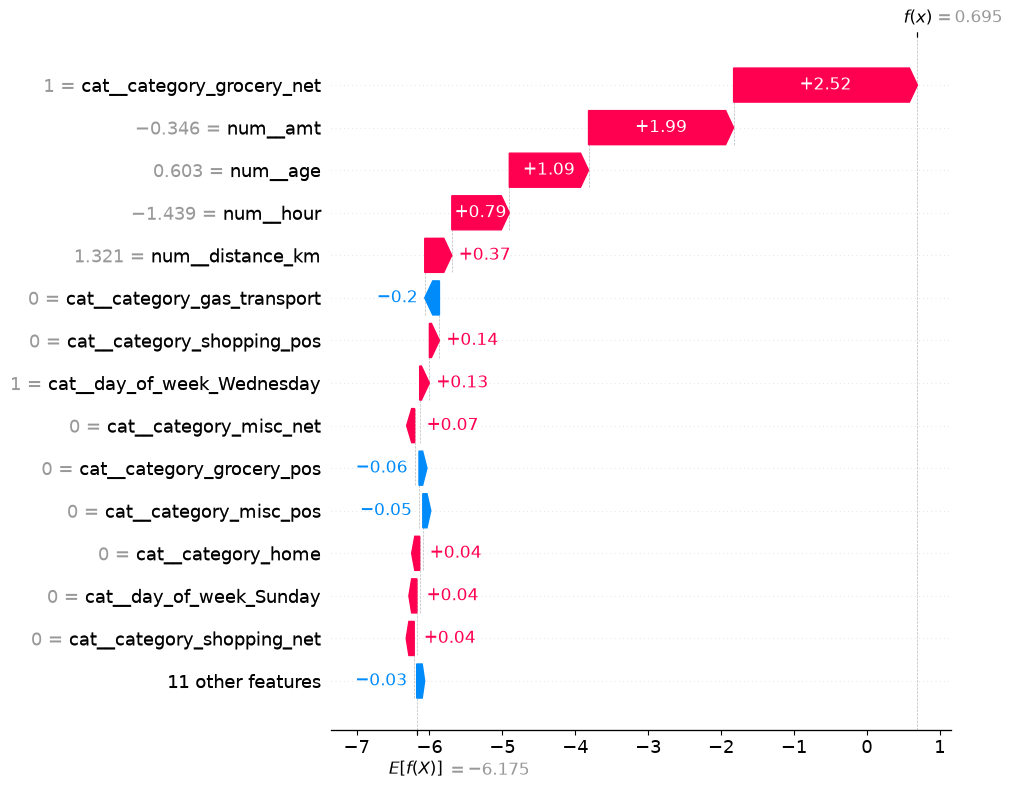

In [6]:
# Explain the selected transaction
shap.plots.waterfall(
    shap_values[transaction_idx],
    max_display=15
)